# Evolutionary modelling of cancer assessment

## Instructions

There are three sections to this assessment; *coding*, *review*, and *interpretation*. Each is given an equal weighting of 10 marks each.

All answers should be completed in a word document and submitted on moodle before the end of the session. Late submissions will be penalised.

## Introduction

This assessment involves visualising, analysing, and interpreting data from a lineage tracing experiment (Q1), and a computational model of mutation in aging in the animal derived from these parameters and an estimated mutation rate (Q2, Q3). In the experiment single and double allele knockouts are induced with a coloured label.

![image.png](../images/Cartoon.png)

![image.png](../images/Experiment.png)

## Code (10 marks)

### Q1 (10 marks): 

Three datasets showing how WT, Notch1 het, and Notch1 hom clones grow in a wild type background by counting the number of cells in a clone. Plot and compare these results

In [11]:
import numpy as np
import pandas as pd
from collections import OrderedDict
import matplotlib.pyplot as plt

DATA_FILE = "../data/09-03-21 Final clonal counting dataset.xlsx"

def _read_basal_counts(df):
    return OrderedDict([(t, _read_basal_counts_column(df[t])) for t in df.columns])

def _read_basal_counts_column(col):
    return np.array([v for v in col.values if (not np.isnan(v) and v > 0)], dtype=int)
    
def load_data(target_data, data_file):
    target_data = target_data.lower()
    if target_data == 'wt':
        cols = "C,E,G,I,K"
        times = [10, 14, 28, 63, 91]
    elif target_data == 'het':
        cols = "M,O,Q,S"
        times = [10, 28, 63, 91]
    elif target_data == 'het_ctl':
        cols = "U,W,Y,AA"
        times = [10, 28, 63, 91]
    elif target_data == 'hom':
        cols = "AC,AE,AG"
        times = [10, 14, 28]
    elif target_data == 'hom_ctl':
        cols = "AI,AK,AM"
        times = [10, 14, 28]
        
    df = pd.read_excel(data_file, sheet_name="Splitted data table", skiprows=8, 
                       usecols=cols, header=None, names=times, engine='openpyxl')
    return _read_basal_counts(df)


#example load

wt_data = mean_data('wt', DATA_FILE)


## Note- no internet does not mean no documentation!

If you forget how to run a function, there are built in tools that can assist you.

Use *help* first- it has a lot of information.

You can additionally use *pydoc*, use *inspect*. *pprint* can be useful to make the outputs of different approaches more readable.

In [37]:
help(plt)

Help on module matplotlib.pyplot in matplotlib:

NAME
    matplotlib.pyplot

DESCRIPTION
    `matplotlib.pyplot` is a state-based interface to matplotlib. It provides
    an implicit,  MATLAB-like, way of plotting.  It also opens figures on your
    screen, and acts as the figure GUI manager.

    pyplot is mainly intended for interactive plots and simple cases of
    programmatic plot generation::

        import numpy as np
        import matplotlib.pyplot as plt

        x = np.arange(0, 5, 0.1)
        y = np.sin(x)
        plt.plot(x, y)
        plt.show()

    The explicit object-oriented API is recommended for complex plots, though
    pyplot is still usually used to create the figure and often the Axes in the
    figure. See `.pyplot.figure`, `.pyplot.subplots`, and
    `.pyplot.subplot_mosaic` to create figures, and
    :doc:`Axes API </api/axes_api>` for the plotting methods on an Axes::

        import numpy as np
        import matplotlib.pyplot as plt

        x = np.arang

In [39]:
help(plt.scatter)

Help on function scatter in module matplotlib.pyplot:

scatter(
    x: float | ArrayLike,
    y: float | ArrayLike,
    s: float | ArrayLike | None = None,
    c: ArrayLike | Sequence[ColorType] | ColorType | None = None,
    *,
    marker: MarkerType | None = None,
    cmap: str | Colormap | None = None,
    norm: str | Normalize | None = None,
    vmin: float | None = None,
    vmax: float | None = None,
    alpha: float | None = None,
    linewidths: float | Sequence[float] | None = None,
    edgecolors: Literal['face', 'none'] | ColorType | Sequence[ColorType] | None = None,
    colorizer: Colorizer | None = None,
    plotnonfinite: bool = False,
    data=None,
    **kwargs
) -> PathCollection
    A scatter plot of *y* vs. *x* with varying marker size and/or color.

    Parameters
    ----------
    x, y : float or array-like, shape (n, )
        The data positions.

    s : float or array-like, shape (n, ), optional
        The marker size in points**2 (typographic points are 1/72

In [47]:
import inspect
import pprint

inspect.get_annotations(plt.scatter)

{'x': 'float | ArrayLike',
 'y': 'float | ArrayLike',
 's': 'float | ArrayLike | None',
 'c': 'ArrayLike | Sequence[ColorType] | ColorType | None',
 'marker': 'MarkerType | None',
 'cmap': 'str | Colormap | None',
 'norm': 'str | Normalize | None',
 'vmin': 'float | None',
 'vmax': 'float | None',
 'alpha': 'float | None',
 'linewidths': 'float | Sequence[float] | None',
 'edgecolors': "Literal['face', 'none'] | ColorType | Sequence[ColorType] | None",
 'colorizer': 'Colorizer | None',
 'plotnonfinite': 'bool',
 'return': 'PathCollection'}

In [48]:
pprint.pprint(inspect.getdoc(plt.scatter))

('A scatter plot of *y* vs. *x* with varying marker size and/or color.\n'
 '\n'
 'Parameters\n'
 '----------\n'
 'x, y : float or array-like, shape (n, )\n'
 '    The data positions.\n'
 '\n'
 's : float or array-like, shape (n, ), optional\n'
 '    The marker size in points**2 (typographic points are 1/72 in.).\n'
 "    Default is ``rcParams['lines.markersize'] ** 2``.\n"
 '\n'
 '    The linewidth and edgecolor can visually interact with the marker\n'
 '    size, and can lead to artifacts if the marker size is smaller than\n'
 '    the linewidth.\n'
 '\n'
 '    If the linewidth is greater than 0 and the edgecolor is anything\n'
 "    but *'none'*, then the effective size of the marker will be\n"
 '    increased by half the linewidth because the stroke will be centered\n'
 '    on the edge of the shape.\n'
 '\n'
 '    To eliminate the marker edge either set *linewidth=0* or\n'
 "    *edgecolor='none'*.\n"
 '\n'
 'c : array-like or list of :mpltype:`color` or :mpltype:`color`, optional\

In [49]:
pprint.pprint(inspect.signature(plt.scatter))

<Signature (x: 'float | ArrayLike', y: 'float | ArrayLike', s: 'float | ArrayLike | None' = None, c: 'ArrayLike | Sequence[ColorType] | ColorType | None' = None, *, marker: 'MarkerType | None' = None, cmap: 'str | Colormap | None' = None, norm: 'str | Normalize | None' = None, vmin: 'float | None' = None, vmax: 'float | None' = None, alpha: 'float | None' = None, linewidths: 'float | Sequence[float] | None' = None, edgecolors: "Literal['face', 'none'] | ColorType | Sequence[ColorType] | None" = None, colorizer: 'Colorizer | None' = None, plotnonfinite: 'bool' = False, data=None, **kwargs) -> 'PathCollection'>


In [41]:
import pydoc

pydoc.doc(plt.errorbar)           

Python Library Documentation: function errorbar in module matplotlib.pyplot

errorbar(
    x: float | ArrayLike,
    y: float | ArrayLike,
    yerr: float | ArrayLike | None = None,
    xerr: float | ArrayLike | None = None,
    fmt: str = '',
    *,
    ecolor: ColorType | None = None,
    elinewidth: float | None = None,
    capsize: float | None = None,
    barsabove: bool = False,
    lolims: bool | ArrayLike = False,
    uplims: bool | ArrayLike = False,
    xlolims: bool | ArrayLike = False,
    xuplims: bool | ArrayLike = False,
    errorevery: int | tuple[int, int] = 1,
    capthick: float | None = None,
    data=None,
    **kwargs
) -> ErrorbarContainer
    Plot y versus x as lines and/or markers with attached errorbars.

    *x*, *y* define the data locations, *xerr*, *yerr* define the errorbar
    sizes. By default, this draws the data markers/lines as well as the
    errorbars. Use fmt='none' to draw errorbars without any data markers.

    .. versionadded:: 3.7
       Caps

In [50]:
# Built in options from jupyter

plt.scatter??

Signature:
plt.scatter(
    x: 'float | ArrayLike',
    y: 'float | ArrayLike',
    s: 'float | ArrayLike | None' = None,
    c: 'ArrayLike | Sequence[ColorType] | ColorType | None' = None,
    *,
    marker: 'MarkerType | None' = None,
    cmap: 'str | Colormap | None' = None,
    norm: 'str | Normalize | None' = None,
    vmin: 'float | None' = None,
    vmax: 'float | None' = None,
    alpha: 'float | None' = None,
    linewidths: 'float | Sequence[float] | None' = None,
    edgecolors: "Literal['face', 'none'] | ColorType | Sequence[ColorType] | None" = None,
    colorizer: 'Colorizer | None' = None,
    plotnonfinite: 'bool' = False,
    data=None,
    **kwargs,
) -> 'PathCollection'
Docstring:
A scatter plot of *y* vs. *x* with varying marker size and/or color.

Parameters
----------
x, y : float or array-like, shape (n, )
    The data positions.

s : float or array-like, shape (n, ), optional
    The marker size in points**2 (typographic points are 1/72 in.).
    Default is ``rc

In [51]:
# Can't remember a function? List them with inspect

inspect.getmembers(plt)

[('AbstractContextManager', contextlib.AbstractContextManager),
 ('Annotation', matplotlib.text.Annotation),
 ('Arrow', matplotlib.patches.Arrow),
 ('Artist', matplotlib.artist.Artist),
 ('AutoLocator', matplotlib.ticker.AutoLocator),
 ('AxLine', matplotlib.lines.AxLine),
 ('Axes', matplotlib.axes._axes.Axes),
 ('BackendFilter', <enum 'BackendFilter'>),
 ('Button', matplotlib.widgets.Button),
 ('Circle', matplotlib.patches.Circle),
 ('Colorizer', matplotlib.colorizer.Colorizer),
 ('ColorizingArtist', matplotlib.colorizer.ColorizingArtist),
 ('Colormap', matplotlib.colors.Colormap),
 ('Enum', <enum 'Enum'>),
 ('ExitStack', contextlib.ExitStack),
 ('Figure', matplotlib.figure.Figure),
 ('FigureBase', matplotlib.figure.FigureBase),
 ('FigureCanvasBase', matplotlib.backend_bases.FigureCanvasBase),
 ('FigureManagerBase', matplotlib.backend_bases.FigureManagerBase),
 ('FixedFormatter', matplotlib.ticker.FixedFormatter),
 ('FixedLocator', matplotlib.ticker.FixedLocator),
 ('FormatStrFormatter

## Example response

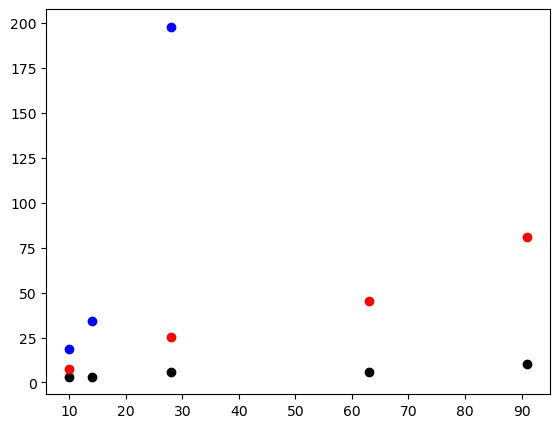

In [21]:
def mean_data(target_data, data_file):
    data = load_data(target_data, data_file)
    mean_dict = OrderedDict()
    for time in data.keys():
        mean_dict[time]=np.mean(data[time])
    return mean_dict

plt.figure(figsize=(6.5, 5))

wt_times = tmean.keys()
wt = tmean.values()

homtimes = mean_data('hom', DATA_FILE).keys()
hettimes = mean_data('het', DATA_FILE).keys()

homtmean = mean_data('hom', DATA_FILE).values()
hettmean = mean_data('het', DATA_FILE).values()

colour_wt = 'k'
colour_het = 'r'
colour_hom = 'b'

plt.scatter(wt_times, wt, label='+/+ data', c=colour_wt)
plt.scatter(hettimes, hettmean, label='+/- data', c=colour_het)
plt.scatter(homtimes, homtmean, label='-/- data', c=colour_hom)


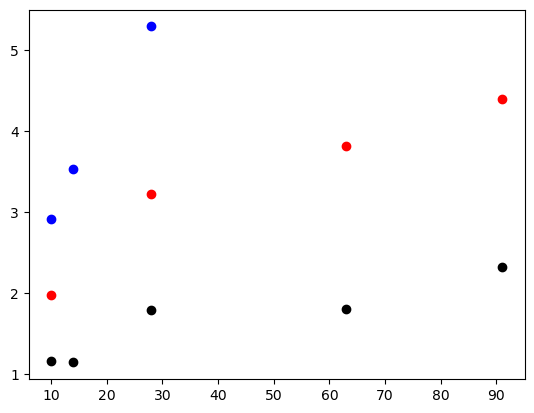

In [27]:

plt.scatter(wt_times, np.log((list(wt))), label='+/+ data', c=colour_wt)
plt.scatter(hettimes, np.log(list(hettmean)), label='+/- data', c=colour_het)
plt.scatter(homtimes, np.log(list(homtmean)), label='-/- data', c=colour_hom)

<ErrorbarContainer object of 3 artists>

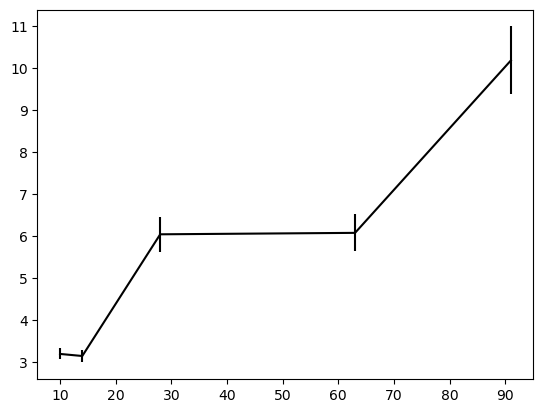

In [35]:
from scipy.stats import sem

def sem_data(target_data, data_file):
    data = load_data(target_data, data_file)
    mean_dict = OrderedDict()
    for time in data.keys():
        mean_dict[time]=sem(data[time])
    return mean_dict

wt_sem = sem_data("WT", DATA_FILE).values()
het_sem = sem_data("HET", DATA_FILE).values()
hom_sem = sem_data("HOM", DATA_FILE).values()

plt.errorbar(wt_times, wt, yerr=wt_sem, label='+/+ data', c=colour_wt )

<ErrorbarContainer object of 3 artists>

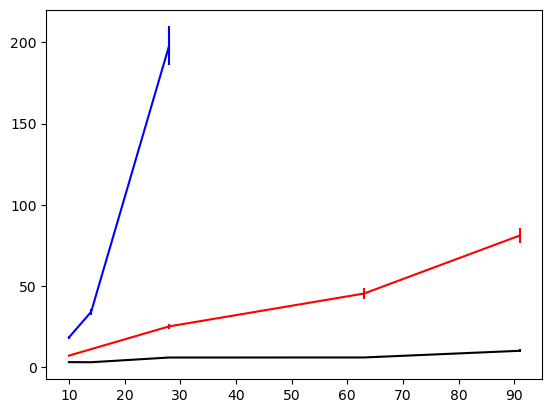

In [36]:
plt.errorbar(wt_times, wt, yerr=wt_sem, label='+/+ data', c=colour_wt )
plt.errorbar(hettimes, (list(hettmean)), yerr=het_sem, label='+/- data', c=colour_het)
plt.errorbar(homtimes, (list(homtmean)), yerr=hom_sem, label='-/- data', c=colour_hom)

## Review (10 marks)

### Q2 (10 marks):

A computational model was derived from the data including some suspected genetic interactions between genes. A LLM model was used to generate a Sankey diagram function from the library, using the following prompt

>I'm working with the Python package `clone-competition-simulation` (pip: `clone-competition-simulation`, GitHub: `michaelhall28/clone-competition-simulation`). I'm using it to run WF2D epistatic fitness simulations of somatic evolution in epithelial tissue, modelling clonal competition between Notch1 (two alleles, het/hom), Notch2, and Trp53 mutations on a hexagonal grid.

>Before answering any questions, please download and inspect the actual installed source by running `pip download clone-competition-simulation --no-deps -d /tmp/ccs` and extracting it, since the documentation is often wrong and APIs differ between versions. Always verify method signatures, attribute names, and field names from the source rather than assuming.

>Please propose a python function that generates a sankey plot based on genotype from the data

Examine the function and the output. 

a) Give a brief overview of how the function is working
b) What can you interpret from this diagram?
c) The final graph doesn't look as I expected. What is non-standard about this Sankey diagram? How would you improve it? 

In [54]:
from clone_competition_simulation.parameters import Parameters, TimeParameters, PopulationParameters, LabelParameters, FitnessParameters
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
from collections import namedtuple
import matplotlib.cm as cm
from matplotlib.colors import Normalize


from clone_competition_simulation import (
    Gene,
    FitnessCalculator,
    FixedValue, 
    multiply_fitness,
    replace_fitness,
    PlottingParameters, 
    ColourRule, 
    PlotColourMaps,
    FeatureValue, 
    CloneFeature,
    EpistaticEffect
)

from clone_competition_simulation.plotting.animator import HexAnimator


In [55]:
# Parameters
NOTCH1_HOM_FITNESS = 7.0
NOTCH1_HET_FITNESS = 2.3

DIVISION_RATE = 0.27
MUTATION_RATE = 0.000005
NUM_SIMS = 10
NUM_SAMPLES = 200
GRID_WIDTH = 1680
GRID_SIZE = GRID_WIDTH ** 2 #500 ** 2
MAX_TIME = 750 #5000

POPULATION_SIZE = 35

np.random.seed(0)


def sim_haploinsufficient(cell_x, mutation_rate, max_time, plotInfo=PlottingParameters(figsize=None,plot_colour_maps=None)):
    
    alleles = [Gene(name='Notch1_allele1', mutation_distribution=FixedValue(NOTCH1_HET_FITNESS), synonymous_proportion=0),
               Gene(name='Notch1_allele2', mutation_distribution=FixedValue(NOTCH1_HET_FITNESS), synonymous_proportion=0),
              ]

    epistatics = [EpistaticEffect(name='Notch1_hom', gene_names=['Notch1_allele1', 'Notch1_allele2'], fitness_distribution=FixedValue(NOTCH1_HOM_FITNESS)),
                 ]

    fit_calc = FitnessCalculator(
        genes = alleles,
        combine_mutations = replace_fitness,
        epistatics = epistatics,
        multi_gene_array=True,
    )

    fitness_combinations = fit_calc.plot_fitness_combinations()
    print(f"Fitness combinations:  {fitness_combinations}")
    plt.show()

    initial_grid = np.zeros((cell_x,cell_x), dtype=int)
        
    p = Parameters(algorithm='WF2D', 
           population=PopulationParameters(initial_grid=initial_grid,cell_in_own_neighbourhood=True),
           times=TimeParameters(max_time=max_time, division_rate=DIVISION_RATE), 
           fitness=FitnessParameters(mutation_rates=mutation_rate,#0.01,
                                     fitness_calculator=fit_calc
                                    ),
           plotting=plotInfo

          )

    s = p.get_simulator()
    s.run_sim()
    return s

Fitness combinations:  Background                         1.0
Notch1_allele1                     2.3
Notch1_allele2                     2.3
Notch1_allele1 + Notch1_allele2    7.0
dtype: float64


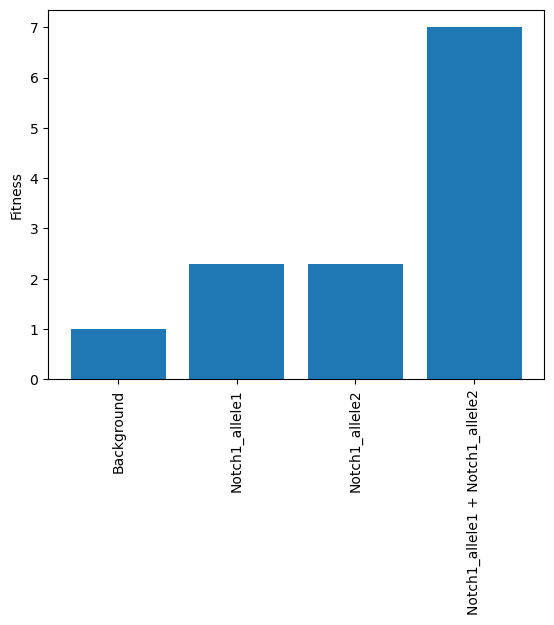

18:42:47 | DEBUG | Times rounded to match simulation steps:  Times used: [  0.           7.40740741  14.81481481  22.22222222  29.62962963
  37.03703704  44.44444444  51.85185185  59.25925926  66.66666667
  74.07407407  81.48148148  88.88888889  96.2962963  103.7037037
 111.11111111 118.51851852 125.92592593 133.33333333 140.74074074
 148.14814815 155.55555556 162.96296296 170.37037037 177.77777778
 185.18518519 196.2962963  203.7037037  211.11111111 218.51851852
 225.92592593 233.33333333 240.74074074 248.14814815 255.55555556
 262.96296296 270.37037037 277.77777778 285.18518519 292.59259259
 300.         307.40740741 314.81481481 322.22222222 329.62962963
 337.03703704 344.44444444 351.85185185 359.25925926 366.66666667
 374.07407407 381.48148148 388.88888889 396.2962963  403.7037037
 411.11111111 418.51851852 425.92592593 433.33333333 440.74074074
 448.14814815 455.55555556 462.96296296 470.37037037 477.77777778
 485.18518519 492.59259259 500.         507.40740741 514.81481481
 522.

Output()

In [57]:
s = sim_haploinsufficient(GRID_WIDTH, MUTATION_RATE,MAX_TIME)

In [58]:
## LLM output below

from __future__ import annotations

from collections import defaultdict
from typing import Sequence

import numpy as np
import plotly.graph_objects as go


# ---------------------------------------------------------------------------
# Colour palette (Tableau-10 extended)
# ---------------------------------------------------------------------------
_DEFAULT_PALETTE = [
    "#4e79a7",  # blue         – usually assigned to WT
    "#f28e2b",  # orange
    "#e15759",  # red
    "#76b7b2",  # teal
    "#59a14f",  # green
    "#edc948",  # yellow
    "#b07aa1",  # purple
    "#ff9da7",  # pink
    "#9c755f",  # brown
    "#bab0ac",  # grey
    "#17becf",  # cyan
    "#bcbd22",  # yellow-green
]

_OTHER_LABEL = "(other)"
_UNRESOLVED_LABEL = "(unresolved)"


# ---------------------------------------------------------------------------
# Public API
# ---------------------------------------------------------------------------

def genotype_sankey(
    sim,
    time_points: Sequence[float] | None = None,
    n_time_points: int = 8,
    min_clone_fraction: float = 0.01,
    exclude_synonymous: bool = True,
    title: str = "Genotype flow",
    width: int = 1000,
    height: int = 580,
    palette: list[str] | None = None,
    colormap: dict[str, str] | None = None,
) -> go.Figure:
    """Build a Sankey diagram showing population flow between genotypes over time.

    Parameters
    ----------
    sim : BaseSimClass
        A finished simulation.  Must have been run with ``run_sim()`` and
        had ``change_sparse_to_csr()`` called on it.
    time_points : sequence of float, optional
        Exact sample times to use as Sankey layers.  Values are matched to
        the nearest recorded sample using ``sim._convert_time_to_index``.
        If omitted, ``n_time_points`` evenly-spaced times are chosen.
    n_time_points : int, default 8
        Number of evenly-spaced layers when ``time_points`` is None.
        Ignored when ``time_points`` is supplied.  Keep ≤ 10 for readability.
    min_clone_fraction : float, default 0.01
        Genotypes that never exceed this fraction of total population are
        merged into a single "(other)" node.
    exclude_synonymous : bool, default True
        When True, synonymous mutations (clone IDs in ``sim.s_muts``) are
        transparent to genotype composition — the clone inherits its parent's
        genotype unchanged.  Set to False to treat every mutation as
        genotype-changing.
    title : str
        Figure title.
    width, height : int
        Figure dimensions in pixels.
    palette : list[str], optional
        Ordered list of hex colours to cycle through when assigning colours
        to genotypes.  Defaults to a Tableau-10 palette.
    colormap : dict[str, str], optional
        Explicit ``{genotype_label: hex_colour}`` mapping.  Takes precedence
        over ``palette`` for any genotype it covers.

    Returns
    -------
    plotly.graph_objects.Figure
    """
    sim.change_sparse_to_csr()

    # ------------------------------------------------------------------
    # 1. Build genotype for every clone (bottom-up, O(n_clones))
    # ------------------------------------------------------------------
    clone_genotype = _build_genotypes(sim, exclude_synonymous)

    # ------------------------------------------------------------------
    # 2. Choose time indices
    # ------------------------------------------------------------------
    t_indices = _select_time_indices(sim, time_points, n_time_points)
    n_layers = len(t_indices)
    display_times = [sim.times[ti] for ti in t_indices]

    # ------------------------------------------------------------------
    # 3. Population by (canonical) genotype at each layer
    # ------------------------------------------------------------------
    total_pop = int(sim.total_pop)
    visible_genos = _find_visible_genotypes(
        sim, clone_genotype, t_indices, total_pop, min_clone_fraction
    )

    def canonical(g: frozenset) -> frozenset:
        return g if g in visible_genos else frozenset({_OTHER_LABEL})

    pop_by_geno: list[dict[frozenset, int]] = []
    for ti in t_indices:
        col = _pop_col(sim, ti)
        d: dict[frozenset, int] = defaultdict(int)
        for c, pop in enumerate(col):
            if pop > 0:
                d[canonical(clone_genotype[c])] += pop
        pop_by_geno.append(d)

    # ------------------------------------------------------------------
    # 4. Flows between consecutive layers
    # ------------------------------------------------------------------
    flows = _compute_flows(sim, clone_genotype, t_indices, canonical)

    # ------------------------------------------------------------------
    # 5. Sorted genotype list (WT first, then by mutation count, then alpha)
    # ------------------------------------------------------------------
    all_genos: set[frozenset] = set()
    for d in pop_by_geno:
        all_genos.update(d.keys())
    for f in flows:
        for g_src, g_tgt in f:
            all_genos.add(g_src)
            all_genos.add(g_tgt)
    sorted_genos = _sort_genotypes(all_genos)

    # ------------------------------------------------------------------
    # 6. Colour assignment
    # ------------------------------------------------------------------
    pal = palette or _DEFAULT_PALETTE
    geno_colors: dict[str, str] = {}
    for i, g in enumerate(sorted_genos):
        label = _geno_label(g)
        geno_colors[label] = pal[i % len(pal)]
    # Override with any user-supplied entries
    if colormap:
        geno_colors.update(colormap)

    # ------------------------------------------------------------------
    # 7. Build Sankey nodes
    # ------------------------------------------------------------------
    node_id_map: dict[tuple[frozenset, int], int] = {}
    node_labels: list[str] = []
    node_colors: list[str] = []
    node_x: list[float] = []
    node_y: list[float] = []

    for layer_idx in range(n_layers):
        d = pop_by_geno[layer_idx]
        genos_present = [(g, d[g]) for g in sorted_genos if d.get(g, 0) > 0]
        y_positions = _compute_y_positions(genos_present)
        x_val = _layer_x(layer_idx, n_layers)

        for (g, _pop), y_val in zip(genos_present, y_positions):
            key = (g, layer_idx)
            node_id_map[key] = len(node_labels)
            label = _geno_label(g)
            node_labels.append(
                f"{label}"
                f"<br><span style='font-size:10px'>t = {display_times[layer_idx]:.2g}"
                f"  ({_pop:,} cells)</span>"
            )
            node_colors.append(geno_colors.get(label, "#aaaaaa"))
            node_x.append(x_val)
            node_y.append(y_val)

    # ------------------------------------------------------------------
    # 8. Build Sankey links
    # ------------------------------------------------------------------
    link_sources: list[int] = []
    link_targets: list[int] = []
    link_values: list[int] = []
    link_colors: list[str] = []

    for layer_idx, f in enumerate(flows):
        for (g_src, g_tgt), value in f.items():
            key_src = (g_src, layer_idx)
            key_tgt = (g_tgt, layer_idx + 1)
            if key_src not in node_id_map or key_tgt not in node_id_map:
                continue
            link_sources.append(node_id_map[key_src])
            link_targets.append(node_id_map[key_tgt])
            link_values.append(value)
            tgt_label = _geno_label(g_tgt)
            link_colors.append(_hex_to_rgba(geno_colors.get(tgt_label, "#aaaaaa"), alpha=0.35))

    # ------------------------------------------------------------------
    # 9. Assemble figure
    # ------------------------------------------------------------------
    fig = go.Figure(
        go.Sankey(
            arrangement="fixed",
            node=dict(
                label=node_labels,
                color=node_colors,
                x=node_x,
                y=node_y,
                pad=12,
                thickness=18,
                line=dict(color="white", width=0.5),
            ),
            link=dict(
                source=link_sources,
                target=link_targets,
                value=link_values,
                color=link_colors,
            ),
        )
    )

    fig.update_layout(
        title=dict(text=title, font=dict(size=15)),
        font=dict(size=11),
        width=width,
        height=height,
        margin=dict(l=20, r=20, t=50, b=20),
    )

    return fig


# ---------------------------------------------------------------------------
# Internal helpers
# ---------------------------------------------------------------------------

def _build_genotypes(sim, exclude_synonymous: bool) -> list[frozenset]:
    """Derive genotype for every clone in a single bottom-up pass.

    Clone IDs are assigned sequentially (parent always has a lower ID than
    its children), so iterating 0 → n_clones processes parents before children.
    """
    fc = sim.fitness_calculator
    n = len(sim.clones_array)
    genotypes: list[frozenset] = [frozenset()] * n

    for c in range(n):
        parent_id = int(sim.clones_array[c, sim.parent_idx])
        parent_geno = genotypes[parent_id] if parent_id >= 0 else frozenset()

        # Synonymous mutations are genotype-transparent when requested
        if exclude_synonymous and c in sim.s_muts:
            genotypes[c] = parent_geno
            continue

        gene_idx = sim.clones_array[c, sim.gene_mutated_idx]
        if fc is not None and not np.isnan(gene_idx):
            name = fc.get_gene_name(gene_idx)
            genotypes[c] = parent_geno | frozenset([name]) if name else parent_geno
        else:
            genotypes[c] = parent_geno

    return genotypes


def _select_time_indices(sim, time_points, n_time_points: int) -> list[int]:
    if time_points is not None:
        return [sim._convert_time_to_index(t) for t in time_points]
    # Evenly spaced across recorded sample times
    total = len(sim.times)
    step = max(1, (total - 1) / max(n_time_points - 1, 1))
    indices = sorted(set(
        min(total - 1, round(i * step)) for i in range(n_time_points)
    ))
    return indices


def _pop_col(sim, ti: int) -> np.ndarray:
    return np.asarray(sim.population_array[:, ti].todense()).flatten().astype(int)


def _find_visible_genotypes(
    sim, clone_genotype: list[frozenset],
    t_indices: list[int], total_pop: int,
    min_fraction: float,
) -> set[frozenset]:
    visible: set[frozenset] = set()
    for ti in t_indices:
        col = _pop_col(sim, ti)
        d: dict[frozenset, int] = defaultdict(int)
        for c, pop in enumerate(col):
            if pop > 0:
                d[clone_genotype[c]] += pop
        for g, pop in d.items():
            if pop / total_pop >= min_fraction:
                visible.add(g)
    return visible


def _compute_flows(
    sim,
    clone_genotype: list[frozenset],
    t_indices: list[int],
    canonical,
) -> list[dict[tuple[frozenset, frozenset], int]]:
    """Compute (source_genotype, target_genotype) → cell count for each gap."""
    n_clones = len(sim.clones_array)
    # Cache parent lookup
    parent_ids = sim.clones_array[:, sim.parent_idx].astype(int)

    flows = []
    for layer_idx in range(len(t_indices) - 1):
        ti_curr = t_indices[layer_idx]
        ti_next = t_indices[layer_idx + 1]
        col_curr = _pop_col(sim, ti_curr)
        col_next = _pop_col(sim, ti_next)

        f: dict[tuple[frozenset, frozenset], int] = defaultdict(int)
        for c in range(n_clones):
            if col_next[c] == 0:
                continue
            g_tgt = canonical(clone_genotype[c])

            if col_curr[c] > 0:
                # Clone was already present — source is its own genotype
                g_src = canonical(clone_genotype[c])
            else:
                # Clone arose in this interval — walk up to nearest ancestor
                # that had cells at ti_curr
                g_src = _find_source_genotype(
                    c, parent_ids, col_curr, clone_genotype, canonical
                )

            f[(g_src, g_tgt)] += col_next[c]

        flows.append(f)
    return flows


def _find_source_genotype(
    clone_id: int,
    parent_ids: np.ndarray,
    col_curr: np.ndarray,
    clone_genotype: list[frozenset],
    canonical,
) -> frozenset:
    """Walk up the tree to find the genotype of the nearest ancestor with cells."""
    visited = clone_id
    pid = parent_ids[clone_id]
    while pid >= 0:
        if col_curr[pid] > 0:
            return canonical(clone_genotype[pid])
        pid = parent_ids[pid]
    # No ancestor had cells at this time — route to unresolved
    return frozenset({_UNRESOLVED_LABEL})


def _sort_genotypes(genos: set[frozenset]) -> list[frozenset]:
    """WT first, then by number of mutations, then alphabetically within size."""
    def key(g: frozenset):
        if not g:
            return (0, [])
        label = next(iter(g))
        if label in (_OTHER_LABEL, _UNRESOLVED_LABEL):
            return (999, [label])
        return (len(g), sorted(g))
    return sorted(genos, key=key)


def _geno_label(g: frozenset) -> str:
    if not g:
        return "WT"
    items = sorted(g)
    if len(items) == 1 and items[0] in (_OTHER_LABEL, _UNRESOLVED_LABEL):
        return items[0]
    return " + ".join(items)


def _layer_x(layer_idx: int, n_layers: int) -> float:
    """Map layer index to an x position in [0.02, 0.98]."""
    if n_layers == 1:
        return 0.5
    return 0.02 + 0.96 * layer_idx / (n_layers - 1)


def _compute_y_positions(genos_and_pops: list[tuple[frozenset, int]]) -> list[float]:
    """Stack genotype nodes proportionally, top-to-bottom, with small gaps."""
    if not genos_and_pops:
        return []
    n = len(genos_and_pops)
    gap = 0.02
    total = sum(p for _, p in genos_and_pops)
    if total == 0:
        return [0.5] * n
    available = max(0.1, 1.0 - gap * (n - 1))
    positions = []
    y = 0.0
    for _, pop in genos_and_pops:
        frac = (pop / total) * available
        # clamp midpoint away from 0 and 1 so plotly doesn't clip the node
        mid = min(0.98, max(0.02, y + frac / 2))
        positions.append(mid)
        y += frac + gap
    return positions


def _hex_to_rgba(hex_color: str, alpha: float = 0.4) -> str:
    h = hex_color.lstrip("#")
    r, g, b = int(h[0:2], 16), int(h[2:4], 16), int(h[4:6], 16)
    return f"rgba({r},{g},{b},{alpha})"

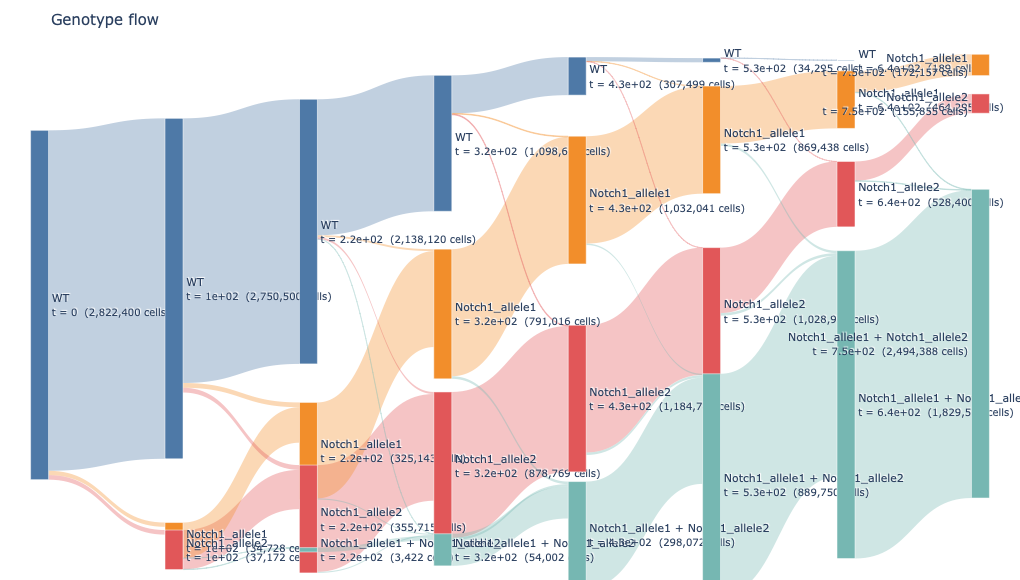

In [60]:
genotype_sankey(s)

## Interpretation (10 marks)

### Q3 (10 marks): 

![image.png](../Images/Haplo.png)

The graph above shows a comparison between the fitted model of takeover two different models, using a common mutation rate using derived fitness parameters for the HET and HOM clones. In one model the Notch1 is considered to be haplosufficient and in the other haploinsufficient. Takeover data from an experimental model is compared to the computational models.

a) What is the biological difference between being haplosufficient and haploinsufficient?

b) What are the implications of the comparison with data for Notch1?

c) What are the broader implications for clonal competion in the tissue?